# Interpretation and recommendations

Automated Analytics Pipeline: Raw Data to PostgreSQL and Dashboard

Author: Wawan Saputra

Scope: PostgreSQL adalah backend utama dan telah diuji pada database lokal. SQLite tersedia secara eksplisit untuk penggunaan portable. Refresh dijalankan secara manual melalui --refresh; project tidak memasang jadwal otomatis. Dataset latest-vintage bukan arsip vintage historis.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
ROOT = ROOT.resolve()
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))

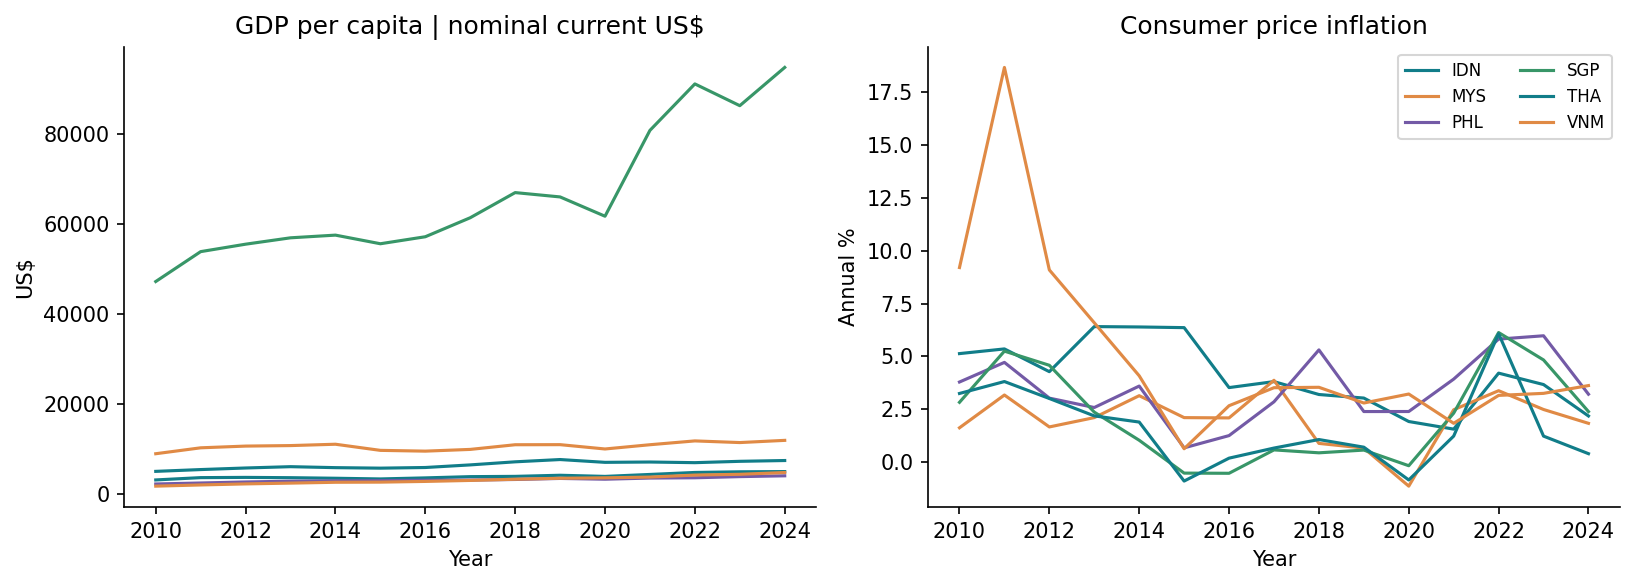

In [2]:
display(Image(filename=str(ROOT / 'outputs/figures/dashboard_preview.png')))

In [3]:
display(Markdown((ROOT / 'outputs/executive_summary.md').read_text(encoding='utf-8')))

# Automated Analytics Pipeline: World Bank to PostgreSQL

Wawan Saputra | Independent Portfolio Project | 2026

## Question and source

Create reliable country-year analytical datasets for six Southeast Asian economies using World Bank GDP per capita, inflation and population, 2010–2024. Units remain explicit; nominal GDP per capita is not a purchasing-power or causal comparison.

## Architecture

Cached public API JSON → explicit schema/domain validation → normalized country and indicator dimensions → observation facts with composite primary key and foreign keys → transactional upserts → analytical SQL pivot and LAG queries → dashboard-ready CSV and Streamlit app. PostgreSQL is the primary backend; SQLite is an explicit portable alternative.

## Actual execution

Backend postgresql; 270 validated rows, 270 stored rows, 270 after repeat load, 90 analytical country-year rows. Database value roundtrip matched the source. Missing numeric values retained as SQL NULL: 0. Database: PostgreSQL 17.6 on x86_64-windows, compiled by msvc-19.44.35213, 64-bit.

## Reliability

Validation precedes writes. Transactions prevent partial dimension/fact loads. Primary keys prevent duplicates, foreign keys enforce dimensions, and repeated loads update existing keys. Refresh validates new API content before replacing the cached snapshot. Logs omit connection credentials. Re-run python -m src.run --refresh for an explicit refresh; no scheduler is installed.

## Limitations and Future Work

Latest-vintage data can be revised; refresh changes snapshots and checksums. No claim of a historical-vintage warehouse or orchestration service. Fixed selected country/indicator/year coverage, no missing-value imputation, no currency or inflation adjustment of nominal GDP. Add migration tooling, freshness alerts, immutable source version history and automated database integration checks for production.

## CV-ready bullets

- Built and executed a normalized postgresql analytics pipeline for 270 public observations with foreign keys, transactional upserts and SQL window functions.

- Verified repeat-load idempotency and exact source-to-database value roundtrip; exported 90 dashboard-ready country-year records.
